In [99]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import kagglehub
import seaborn as sns
import missingno as msno
from data_profiling import ProfileReport
import statsmodels.formula.api as smf
plt.style.use('seaborn-v0_8-whitegrid')


%matplotlib inline
import pyarrow as pa
import fastparquet

pd.set_option('display.max_columns', None)

In [100]:
from project_1_dashboard.config import (
    PROJ_ROOT,
    RAW_DATA_DIR,
    INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR,
    REPORTS_DIR,
    FIGURES_DIR,
)

In [101]:

# Download the dataset from Kaggle then save into raw data directory





# dataset_dir.mkdir(parents=True, exist_ok=True)

# path = kagglehub.dataset_download(
#     "annavictoria/speed-dating-experiment",
#     output_dir=dataset_dir,
# )

# print("Path to dataset files:", path)



# path = kagglehub.dataset_download("lainguyn123/student-performance-factors", output_dir=RAW_DATA_DIR, force_download=True)

# print("Path to dataset files:", path)

In [102]:
raw_spf_df = pd.read_csv(RAW_DATA_DIR / "StudentPerformanceFactors.csv", encoding = "utf-8", delimiter = ",")

In [103]:
raw_spf_df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [104]:
raw_spf_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [105]:
# Create profile report for the dataset
# raw_profile = ProfileReport(raw_spf_df, explorative=True)
# raw_profile.to_file(REPORTS_DIR / "raw_spf_profile.html")

In [106]:
raw_spf_df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [107]:
raw_spf_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

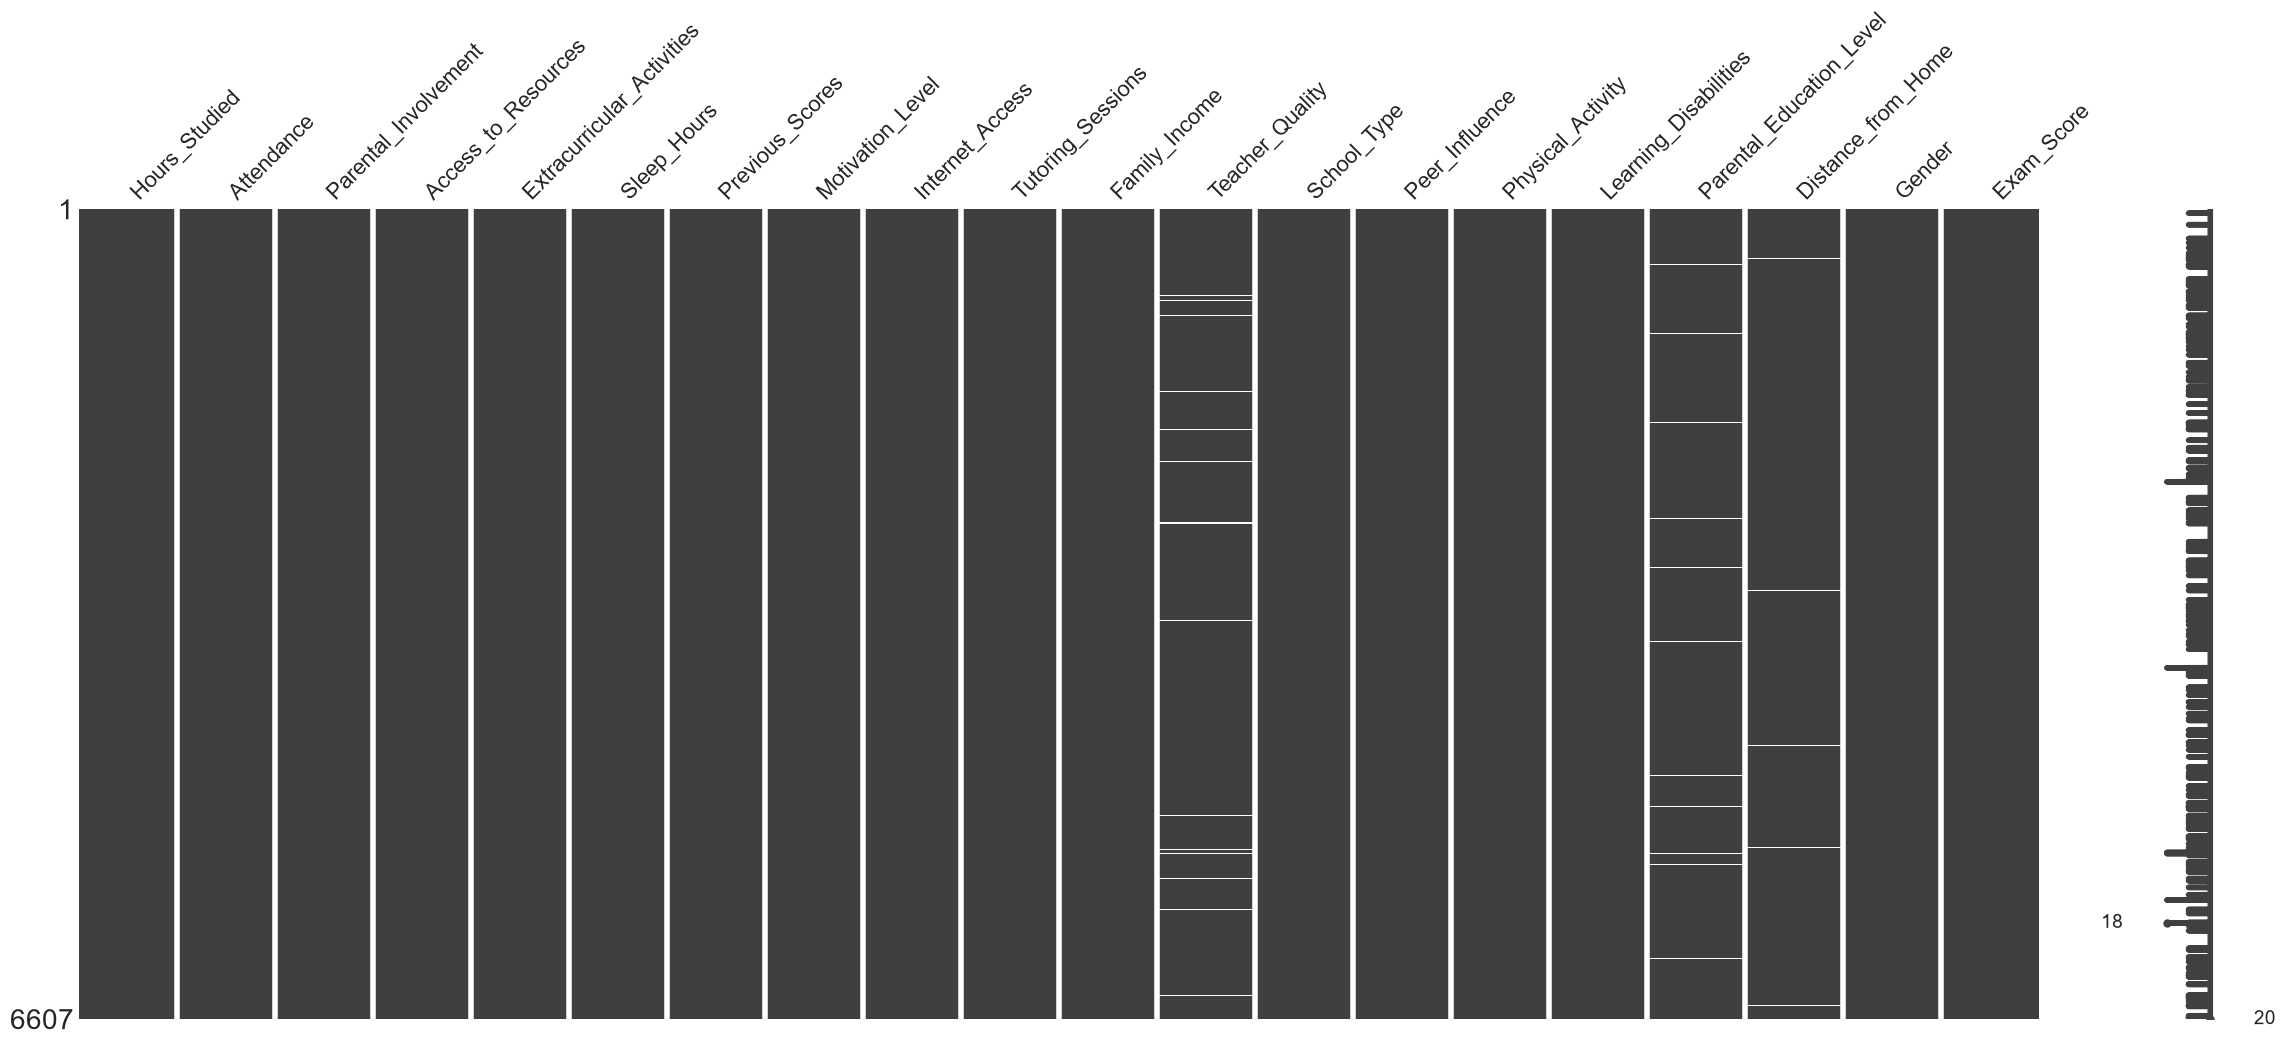

In [108]:
msno.matrix(raw_spf_df)
plt.show()

In [109]:
raw_spf_df[raw_spf_df.isna().any(axis=1)]

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
33,14,60,High,Medium,No,5,50,Medium,Yes,2,Medium,Medium,Public,Neutral,3,No,College,NaN,Female,61
127,17,97,Medium,Medium,No,8,89,Medium,Yes,1,Low,NaN,Public,Neutral,4,No,High School,Far,Male,69
240,15,87,Low,Medium,No,4,54,Medium,Yes,1,Medium,Medium,Public,Neutral,6,No,NaN,Moderate,Male,65
275,23,82,Low,Medium,Yes,8,94,Medium,Yes,1,Medium,Medium,Public,Negative,2,Yes,High School,NaN,Male,66
316,24,90,Low,Low,No,7,83,Medium,Yes,0,Low,Medium,Private,Positive,3,No,College,NaN,Male,68
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6502,23,64,Medium,Medium,No,7,75,Medium,Yes,2,Medium,High,Public,Positive,2,No,NaN,Near,Female,66
6579,9,84,Medium,Medium,No,6,74,Medium,Yes,5,High,NaN,Public,Neutral,2,No,High School,Near,Male,67
6589,22,90,Low,High,No,5,99,Medium,Yes,1,Low,Low,Private,Positive,2,No,College,NaN,Female,70
6594,9,90,High,High,Yes,7,79,Low,Yes,4,High,High,Public,Positive,4,No,High School,NaN,Male,70


In [110]:
silver_df = raw_spf_df.copy()

In [111]:
silver_df.dropna(inplace=True)

In [112]:
silver_df[silver_df.isna().any(axis=1)]

# Dropped rows with missing values, as we have enough data to work with as the missing data would do more harm than good to impute. 



,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score


In [113]:
silver_df.columns = (
    silver_df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"([a-z0-9])([A-Z])", r"\1_\2", regex=True)
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

In [114]:
variable_profile = pd.DataFrame({
    "dtype": silver_df.dtypes,
    "unique_values": silver_df.nunique(),
    "missing_values": silver_df.isna().sum(),
    "cardinality_pct": (silver_df.nunique() / len(silver_df) * 100).round(2)
})

display(variable_profile)

,dtype,unique_values,missing_values,cardinality_pct
hours_studied,int64,41,0,0.64
attendance,int64,41,0,0.64
parental_involvement,object,3,0,0.05
access_to_resources,object,3,0,0.05
extracurricular_activities,object,2,0,0.03
sleep_hours,int64,7,0,0.11
previous_scores,int64,51,0,0.80
motivation_level,object,3,0,0.05
internet_access,object,2,0,0.03
tutoring_sessions,int64,9,0,0.14


In [115]:
cat_cols = silver_df.select_dtypes(include="object").columns

for col in cat_cols:
    print(f"{col}: {silver_df[col].unique()}")

parental_involvement: ['Low' 'Medium' 'High']
access_to_resources: ['High' 'Medium' 'Low']
extracurricular_activities: ['No' 'Yes']
motivation_level: ['Low' 'Medium' 'High']
internet_access: ['Yes' 'No']
family_income: ['Low' 'Medium' 'High']
teacher_quality: ['Medium' 'High' 'Low']
school_type: ['Public' 'Private']
peer_influence: ['Positive' 'Negative' 'Neutral']
learning_disabilities: ['No' 'Yes']
parental_education_level: ['High School' 'College' 'Postgraduate']
distance_from_home: ['Near' 'Moderate' 'Far']
gender: ['Male' 'Female']


In [116]:
# Define variable mappings for ordinal categories

ordinal_mappings = {
    "parental_involvement": ["Low", "Medium", "High"],
    "access_to_resources": ["Low", "Medium", "High"],
    "motivation_level": ["Low", "Medium", "High"],
    "family_income": ["Low", "Medium", "High"],
    "teacher_quality": ["Low", "Medium", "High"],
    "peer_influence": ["Negative", "Neutral", "Positive"],
    "parental_education_level": ["High School", "College", "Postgraduate"],
    "distance_from_home": ["Near", "Moderate", "Far"]
}

for col, order in ordinal_mappings.items():
    silver_df[col] = pd.Categorical(
        silver_df[col],
        categories=order,
        ordered=True
    )

In [117]:
# Map nominal columns into a categorical data type

nominal_cols = [
    "extracurricular_activities",
    "internet_access",
    "school_type",
    "learning_disabilities",
    "gender"
]

silver_df[nominal_cols] = silver_df[nominal_cols].astype("category")

In [118]:
silver_df.head()

,hours_studied,attendance,parental_involvement,access_to_resources,extracurricular_activities,sleep_hours,previous_scores,motivation_level,internet_access,tutoring_sessions,family_income,teacher_quality,school_type,peer_influence,physical_activity,learning_disabilities,parental_education_level,distance_from_home,gender,exam_score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [119]:
numeric_cols = silver_df.select_dtypes(include="number").columns

silver_df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
hours_studied,6378.0,19.977109,5.985460,1.0,16.0,20.0,24.0,44.0
attendance,6378.0,80.020853,11.550723,60.0,70.0,80.0,90.0,100.0
sleep_hours,6378.0,7.034964,1.468033,4.0,6.0,7.0,8.0,10.0
previous_scores,6378.0,75.066165,14.400389,50.0,63.0,75.0,88.0,100.0
tutoring_sessions,6378.0,1.495296,1.233984,0.0,1.0,1.0,2.0,8.0
physical_activity,6378.0,2.972719,1.028926,0.0,2.0,3.0,4.0,6.0
exam_score,6378.0,67.252117,3.914217,55.0,65.0,67.0,69.0,101.0


In [120]:
silver_df[silver_df["exam_score"] > 100]



,hours_studied,attendance,parental_involvement,access_to_resources,extracurricular_activities,sleep_hours,previous_scores,motivation_level,internet_access,tutoring_sessions,family_income,teacher_quality,school_type,peer_influence,physical_activity,learning_disabilities,parental_education_level,distance_from_home,gender,exam_score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101


### Exam Score = 101 Investigation

One record contains an exam score of 101. The value was initially
flagged because it exceeds the assumed 0–100 range.

Reviewing the surrounding variables showed that the student had 98%
attendance, a previous score of 93, 27 hours studied, and five tutoring
sessions. These characteristics are consistent with a high-performing
student.

Because the dataset does not specify whether extra credit is possible,
the value cannot be confirmed as an error. The record will therefore
be retained and treated as a valid extreme value unless documentation
establishes that exam scores are strictly capped at 100.

In [121]:
silver_df.to_csv(PROCESSED_DATA_DIR / "silver_data.csv", index=False)

In [122]:
silver_df["school_type"].unique()

['Public', 'Private']
Categories (2, object): ['Private', 'Public']

<Axes: >

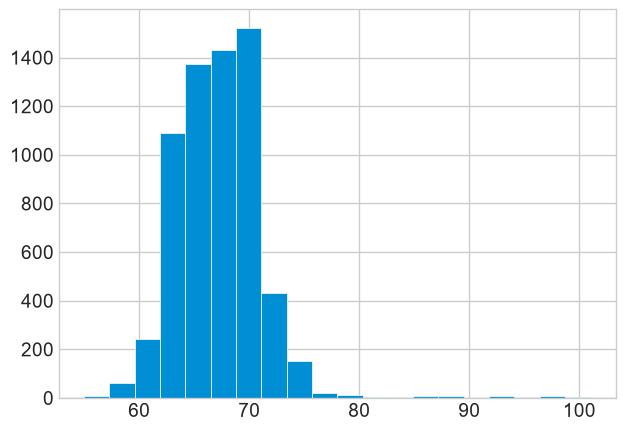

In [123]:
silver_df["exam_score"].hist(bins=20)

<Axes: xlabel='peer_influence'>

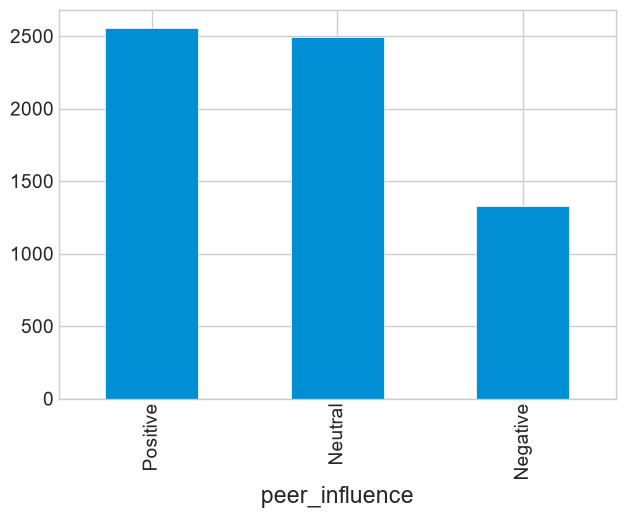

In [124]:
silver_df["peer_influence"].value_counts().plot(kind="bar")

<Axes: xlabel='peer_influence'>

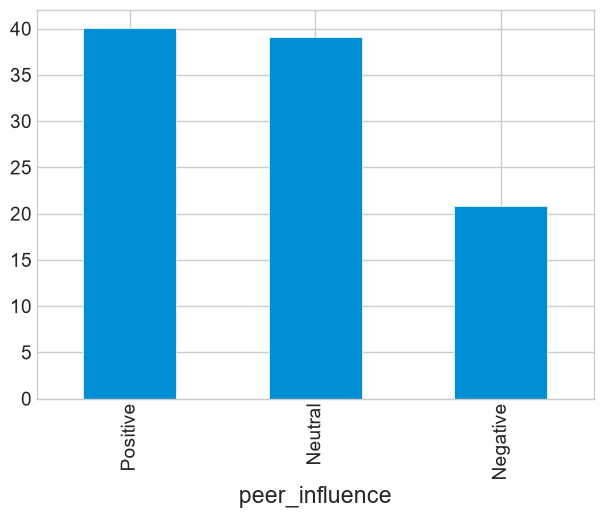

In [125]:
(
    silver_df["peer_influence"]
    .value_counts(normalize=True)
    .mul(100)
    .plot(kind="bar")
)

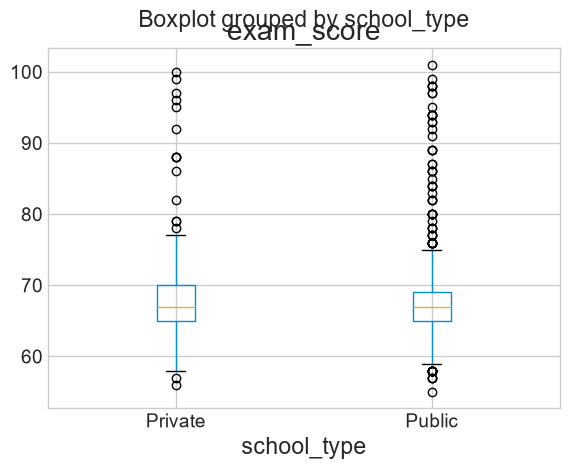

In [126]:
silver_df.boxplot(column="exam_score", by="school_type")
plt.show()

In [127]:
silver_df["school_type"].value_counts()

school_type
Public     4434
Private    1944
Name: count, dtype: int64

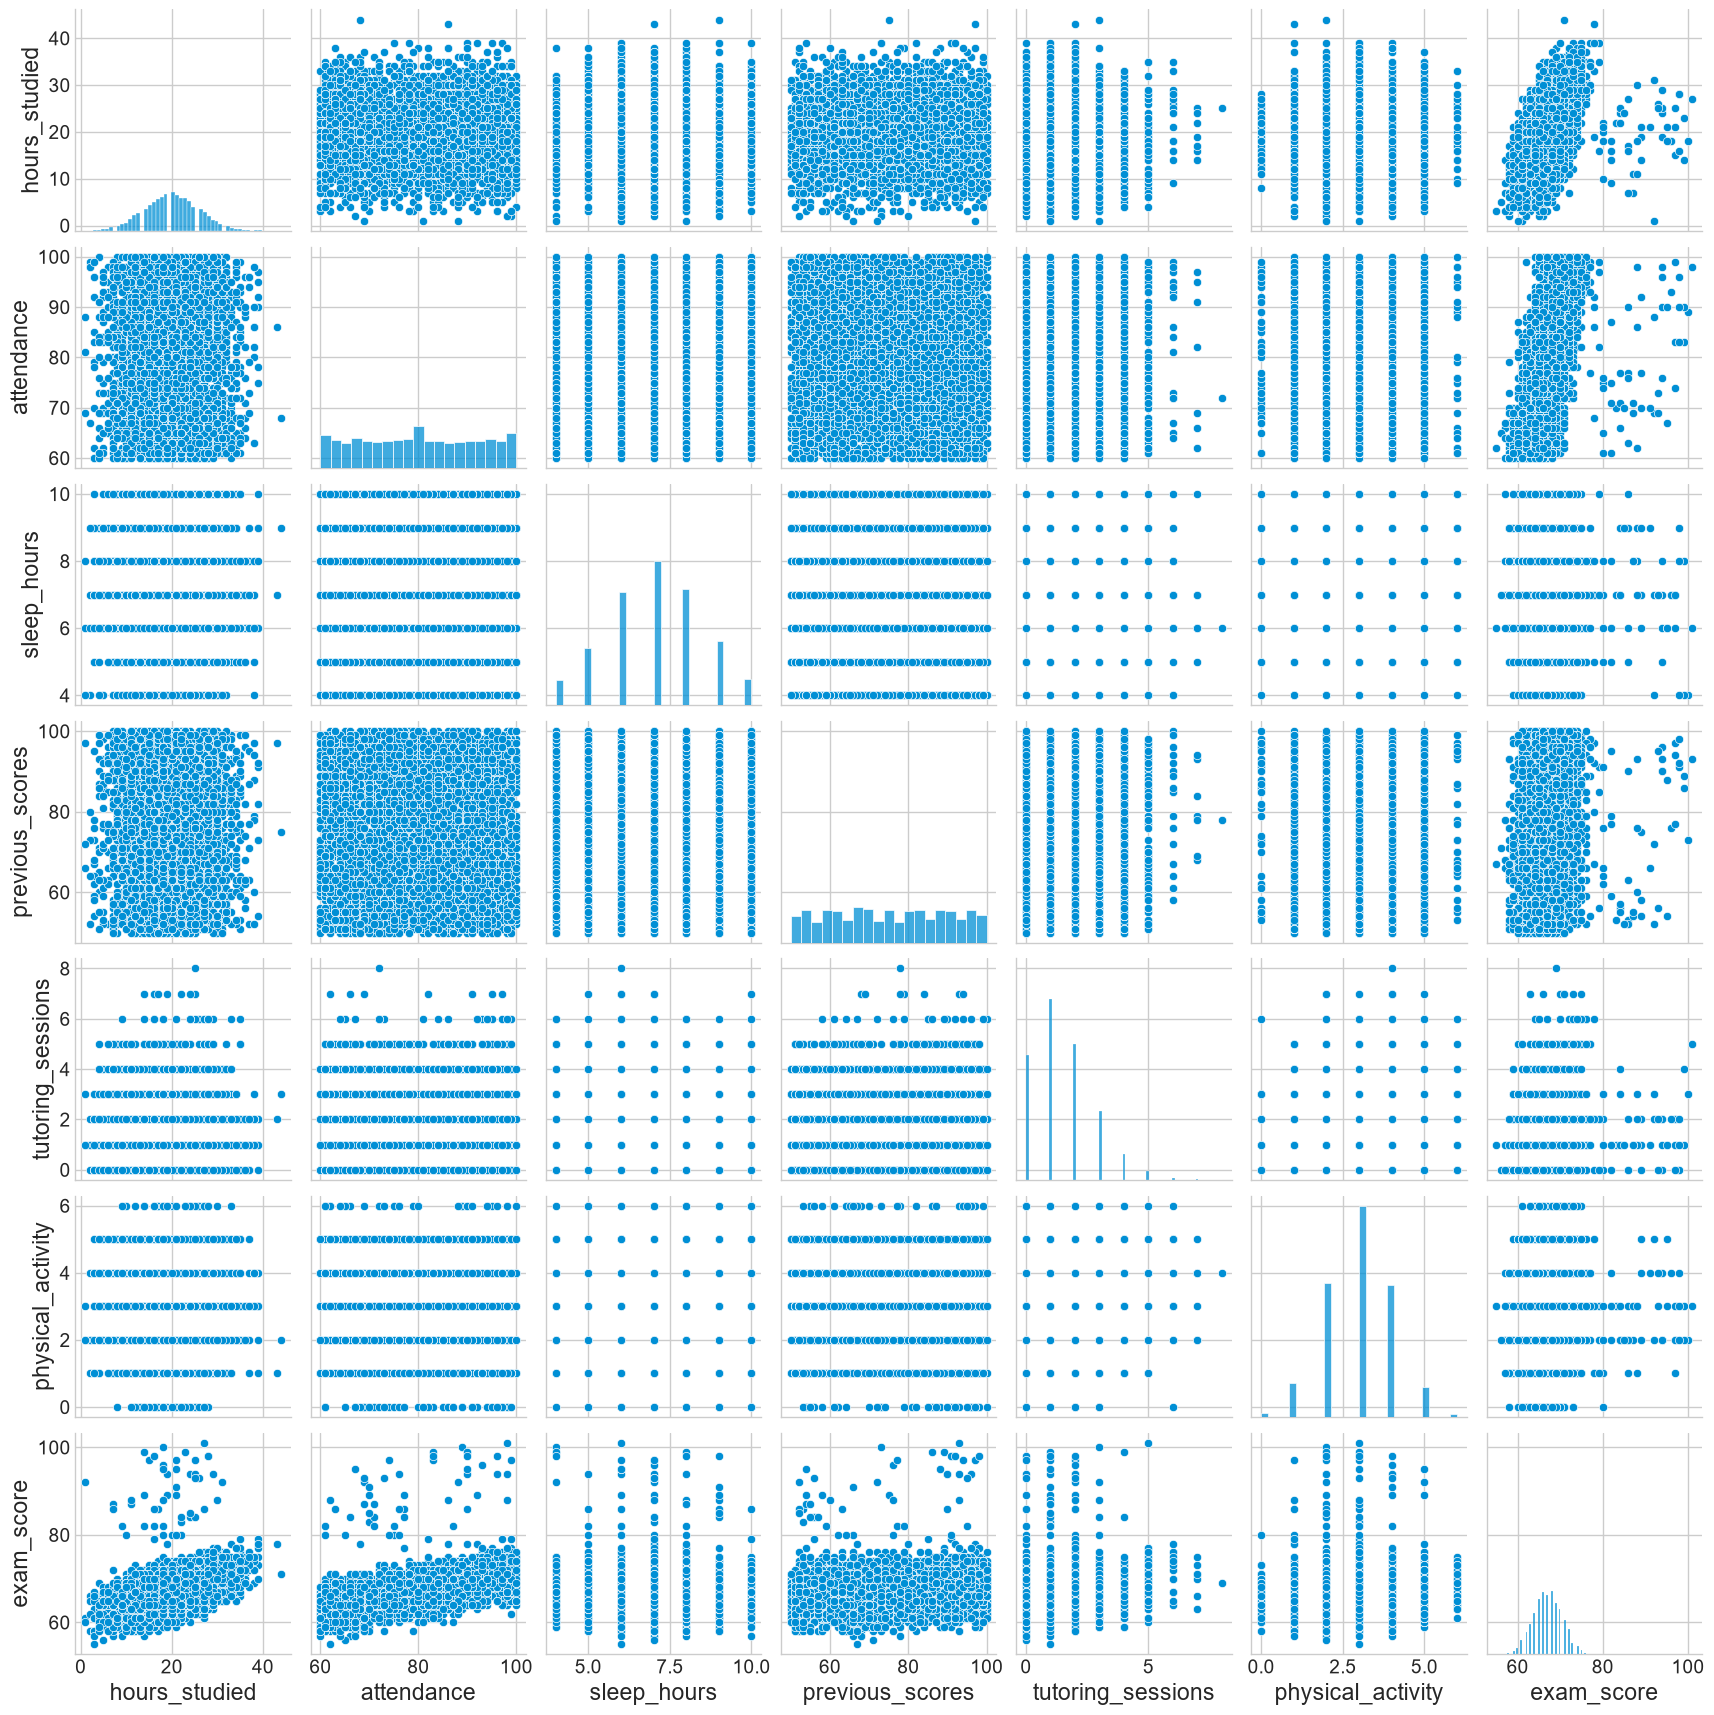

In [128]:
sns.pairplot(silver_df, diag_kind="hist")

In [129]:
sleep_exam = (
    silver_df.groupby("sleep_hours")["exam_score"]
    .agg(["count", "mean", "median"])
    .reset_index()
)



sleep_exam

,sleep_hours,count,mean,median
0,4,296,67.692568,67.0
1,5,668,67.261976,67.0
2,6,1322,67.216339,67.0
3,7,1682,67.263971,67.0
4,8,1354,67.262186,67.0
5,9,753,67.140770,67.0
6,10,303,67.122112,67.0


In [130]:
sleep_exam = (
    silver_df.groupby("tutoring_sessions")["exam_score"]
    .agg(["count", "mean", "median"])
    .reset_index()
)



sleep_exam

,tutoring_sessions,count,mean,median
0,0,1458,66.506859,66.0
1,1,2111,66.998579,67.0
2,2,1586,67.556747,67.0
3,3,800,67.953750,68.0
4,4,296,68.239865,68.0
5,5,101,69.089109,69.0
6,6,18,71.666667,72.5
7,7,7,69.857143,71.0
8,8,1,69.000000,69.0


In [131]:
numeric_df = silver_df.select_dtypes(include="number")

exam_corr = (
    numeric_df
    .corr()["exam_score"]
    .sort_values(ascending=False)
)

exam_corr

exam_score           1.000000
attendance           0.580259
hours_studied        0.445104
previous_scores      0.174283
tutoring_sessions    0.156829
physical_activity    0.025148
sleep_hours         -0.017171
Name: exam_score, dtype: float64

In [132]:
silver_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6378 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   hours_studied               6378 non-null   int64   
 1   attendance                  6378 non-null   int64   
 2   parental_involvement        6378 non-null   category
 3   access_to_resources         6378 non-null   category
 4   extracurricular_activities  6378 non-null   category
 5   sleep_hours                 6378 non-null   int64   
 6   previous_scores             6378 non-null   int64   
 7   motivation_level            6378 non-null   category
 8   internet_access             6378 non-null   category
 9   tutoring_sessions           6378 non-null   int64   
 10  family_income               6378 non-null   category
 11  teacher_quality             6378 non-null   category
 12  school_type                 6378 non-null   category
 13  peer_influence         

In [133]:
categorical_cols = [
    "peer_influence",
    "motivation_level",
    "school_type",
    "gender",
    "teacher_quality",
    "family_income",
    "learning_disabilities"
]





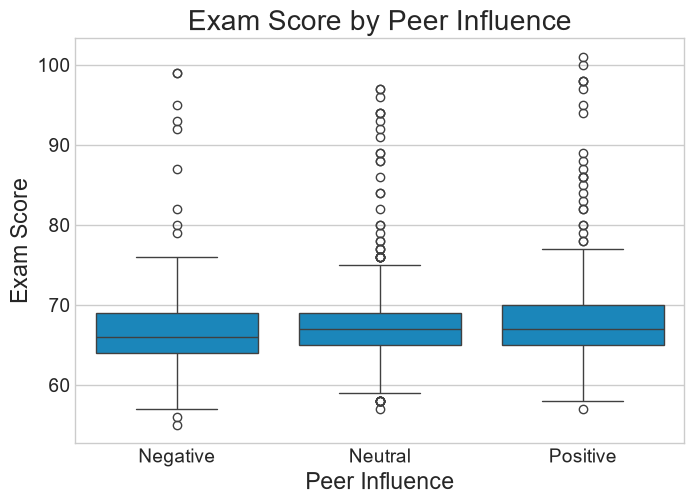

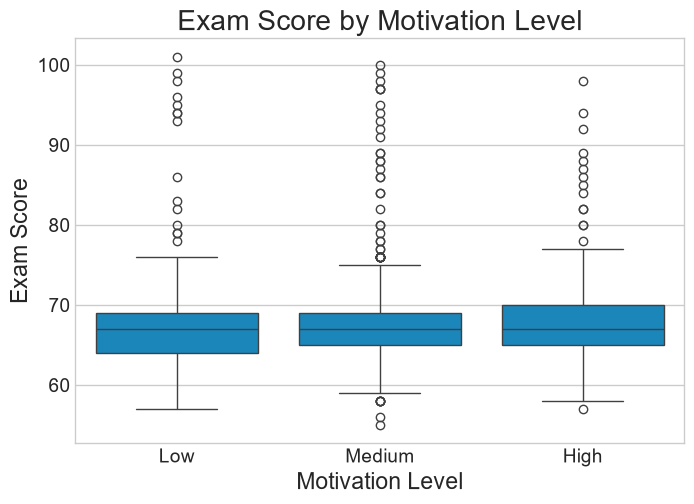

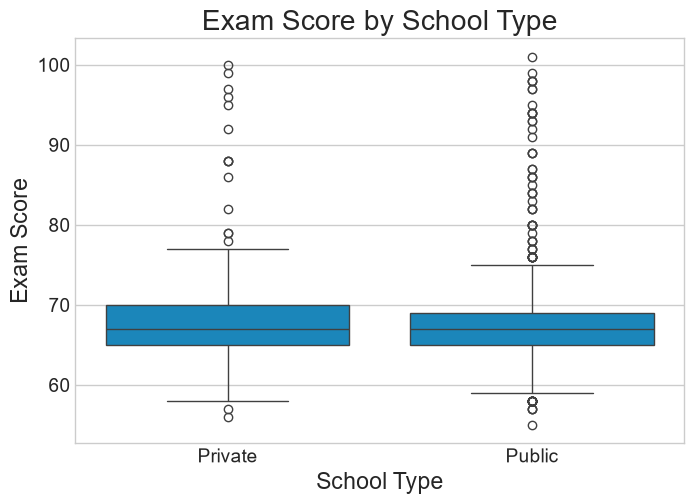

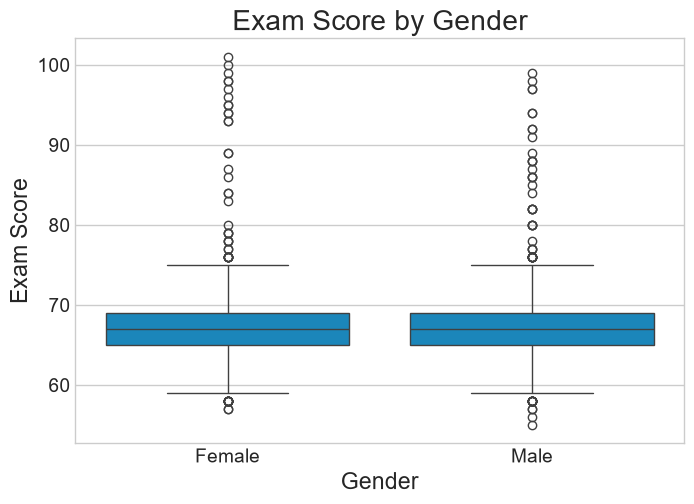

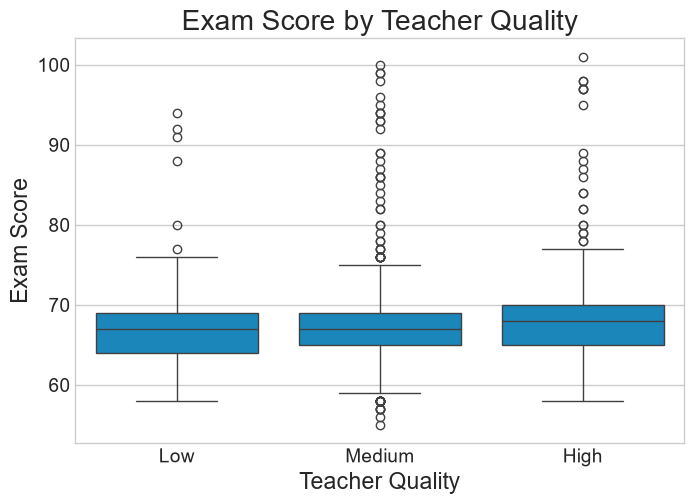

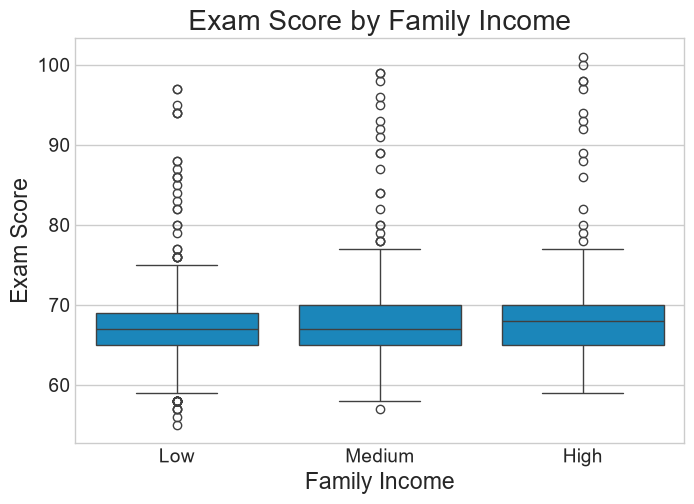

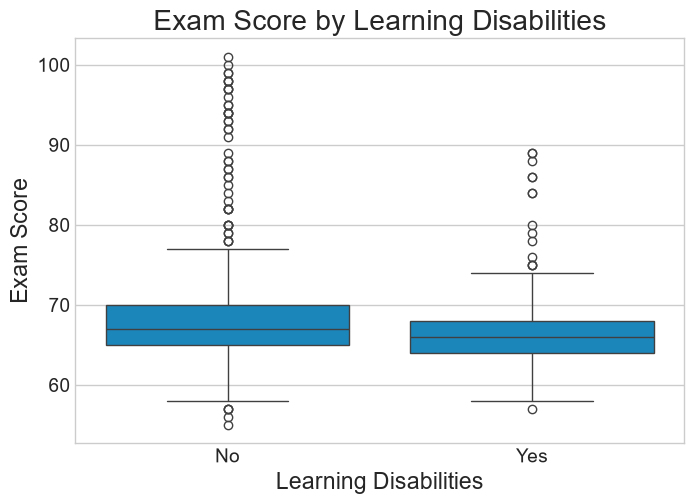

In [134]:
for col in categorical_cols:
    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=silver_df,
        x=col,
        y="exam_score"
    )

    plt.title(
        f"Exam Score by {col.replace('_', ' ').title()}"
    )

    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel("Exam Score")

    plt.show()

In [135]:
category_dummies = pd.get_dummies(
    silver_df[categorical_cols],
    dtype=int
)

category_corr = (
    category_dummies
    .corrwith(silver_df["exam_score"])
    .sort_values(key=abs, ascending=False)
)

category_corr

peer_influence_Negative     -0.087790
family_income_Low           -0.084056
learning_disabilities_Yes   -0.083911
learning_disabilities_No     0.083911
peer_influence_Positive      0.080236
motivation_level_Low        -0.080061
family_income_High           0.073603
teacher_quality_High         0.071660
motivation_level_High        0.062872
teacher_quality_Medium      -0.041750
teacher_quality_Low         -0.040883
family_income_Medium         0.024922
motivation_level_Medium      0.022508
school_type_Public          -0.010868
school_type_Private          0.010868
peer_influence_Neutral      -0.007472
gender_Female                0.004932
gender_Male                 -0.004932
dtype: float64

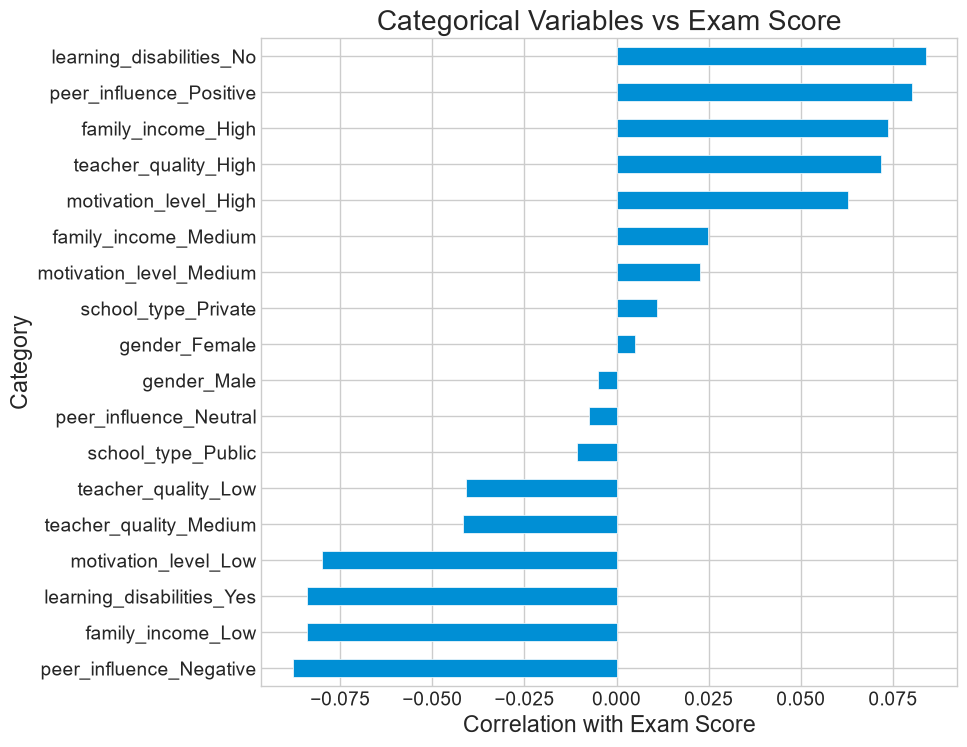

In [136]:
category_corr.sort_values().plot(
    kind="barh",
    figsize=(8, 8)
)

plt.xlabel("Correlation with Exam Score")
plt.ylabel("Category")
plt.title("Categorical Variables vs Exam Score")
plt.show()

In [137]:
silver_df.groupby("peer_influence")["exam_score"].agg(
    ["count", "mean", "median", "std"]
)

C:\Users\saver\AppData\Local\Temp\ipykernel_528\2559248515.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  silver_df.groupby("peer_influence")["exam_score"].agg(


,count,mean,median,std
peer_influence,,,,
Negative,1330,66.582707,66.0,3.861933
Neutral,2495,67.215631,67.0,3.858254
Positive,2553,67.636506,67.0,3.948070


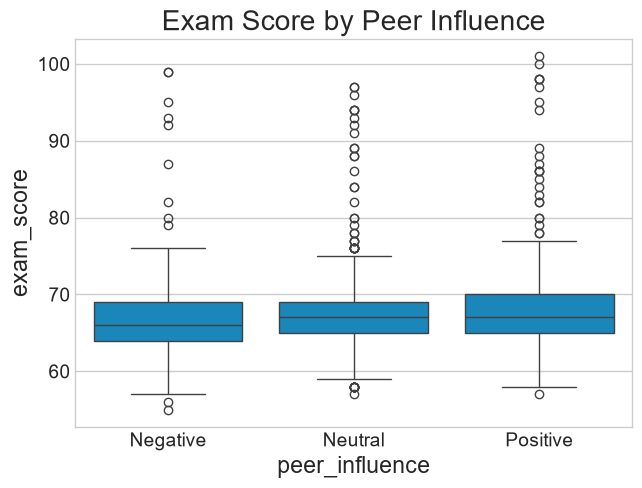

In [138]:


sns.boxplot(
    data=silver_df,
    x="peer_influence",
    y="exam_score"
)

plt.title("Exam Score by Peer Influence")
plt.show()

In [139]:
silver_df.groupby("peer_influence")["exam_score"].quantile(
    [0.05, 0.25, 0.50, 0.75, 0.95]
)

C:\Users\saver\AppData\Local\Temp\ipykernel_528\3574973277.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  silver_df.groupby("peer_influence")["exam_score"].quantile(


peer_influence      
Negative        0.05    61.0
                0.25    64.0
                0.50    66.0
                0.75    69.0
                0.95    72.0
Neutral         0.05    62.0
                0.25    65.0
                0.50    67.0
                0.75    69.0
                0.95    73.0
Positive        0.05    62.0
                0.25    65.0
                0.50    67.0
                0.75    70.0
                0.95    73.0
Name: exam_score, dtype: float64

In [140]:
silver_df["attendance"].describe()

count    6378.000000
mean       80.020853
std        11.550723
min        60.000000
25%        70.000000
50%        80.000000
75%        90.000000
max       100.000000
Name: attendance, dtype: float64

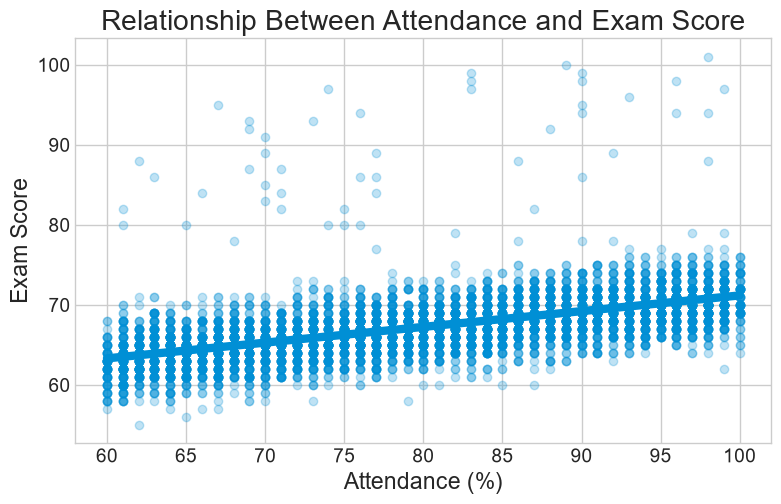

In [142]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=silver_df,
    x="attendance",
    y="exam_score",
    scatter_kws={"alpha": 0.25}
)

plt.xlabel("Attendance (%)")
plt.ylabel("Exam Score")
plt.title("Relationship Between Attendance and Exam Score")

plt.show()

In [143]:
silver_df[["attendance", "exam_score"]].corr()

,attendance,exam_score
attendance,1.000000,0.580259
exam_score,0.580259,1.000000


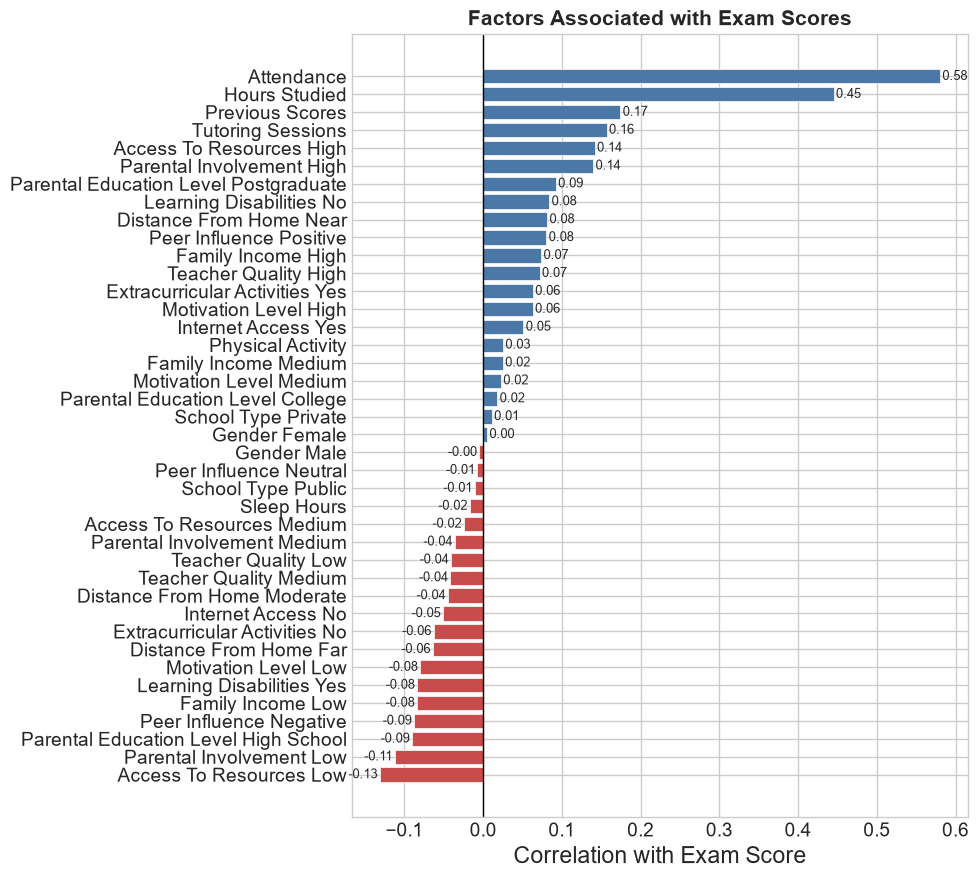

In [144]:


# Separate target from predictors
X = silver_df.drop(columns=["exam_score"])

# Convert categorical variables into dummy variables
X_encoded = pd.get_dummies(X, dtype=int)

# Correlation of every variable/category with exam score
exam_corr = X_encoded.corrwith(
    silver_df["exam_score"]
).sort_values()

# Make labels easier to read
labels = (
    exam_corr.index
    .str.replace("_", " ")
    .str.title()
)

# Positive vs negative colors
colors = [
    "#C94C4C" if value < 0 else "#4C78A8"
    for value in exam_corr
]

plt.figure(figsize=(10, 9))

bars = plt.barh(
    labels,
    exam_corr.values,
    color=colors
)

# Zero reference line
plt.axvline(
    0,
    color="black",
    linewidth=1
)

# Add correlation value to each bar
for bar, value in zip(bars, exam_corr.values):
    plt.text(
        value + (0.003 if value >= 0 else -0.003),
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9
    )

plt.xlabel("Correlation with Exam Score")
plt.ylabel("")
plt.title(
    "Factors Associated with Exam Scores",
    fontsize=15,
    weight="bold"
)

plt.tight_layout()
plt.show()

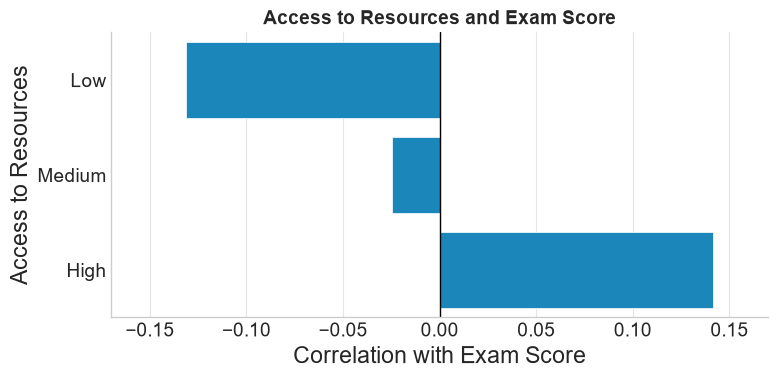

In [159]:

resource_dummies = pd.get_dummies(
    silver_df["access_to_resources"],
    dtype=int
)

resource_corr = (
    resource_dummies
    .corrwith(silver_df["exam_score"])
    .reset_index()
)

resource_corr.columns = [
    "resource_level",
    "correlation"
]

fig, ax = plt.subplots(figsize=(8, 4))

sns.barplot(
    data=resource_corr,
    x="correlation",
    y="resource_level",
    ax=ax
)

# Zero reference line
ax.axvline(
    0,
    color="black",
    linewidth=1
)

# Light vertical gridlines
ax.xaxis.grid(
    True,
    alpha=0.5,
    linewidth=0.8
)

ax.yaxis.grid(False)

# Put gridlines behind bars
ax.set_axisbelow(True)

# Add some breathing room on both sides
max_corr = resource_corr["correlation"].abs().max()

ax.set_xlim(
    -max_corr * 1.2,
    max_corr * 1.2
)

ax.set_title(
    "Access to Resources and Exam Score",
    fontsize=14,
    weight="bold"
)

ax.set_xlabel("Correlation with Exam Score")
ax.set_ylabel("Access to Resources")

sns.despine()

plt.tight_layout()
plt.show()

In [148]:
silver_df["hours_studied"].describe()

count    6378.000000
mean       19.977109
std         5.985460
min         1.000000
25%        16.000000
50%        20.000000
75%        24.000000
max        44.000000
Name: hours_studied, dtype: float64

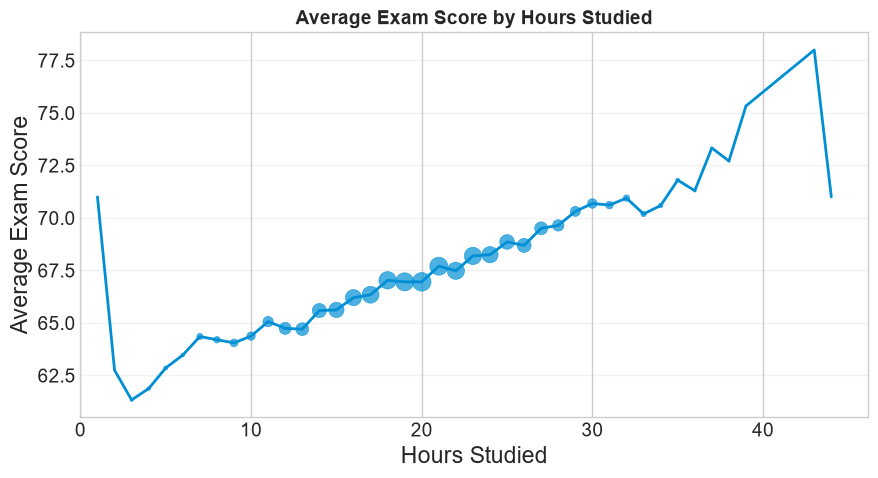

In [161]:
import matplotlib.pyplot as plt

study_summary = (
    silver_df.groupby("hours_studied")["exam_score"]
    .agg(["mean", "count"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    study_summary["hours_studied"],
    study_summary["mean"],
    linewidth=2
)

ax.scatter(
    study_summary["hours_studied"],
    study_summary["mean"],
    s=study_summary["count"] * 0.4,
    alpha=0.7
)

ax.set_xlim(left=0)
ax.margins(x=0)

ax.set_title(
    "Average Exam Score by Hours Studied",
    fontsize=14,
    weight="bold"
)

ax.set_xlabel("Hours Studied")
ax.set_ylabel("Average Exam Score")

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()